# PART 6. 유사 상품 추천 (규칙 기반 vs KNN)

> **핵심 질문: 같은 카테고리면 비슷한 상품일까?**

## 📋 한눈에 보기

**작업 흐름**
```
1. 원본 CSV에서 상품별 특징 만들기 (상품 1개 = 1행)
2. 거래 3건 이상 · 상위 15개 카테고리 · 약 2,500개로 줄이기
3. 추천 ① 같은 카테고리 랜덤
4. 추천 ② + 가격 ±20% 조건
5. 추천 ③ KNN (가격·무게·크기·사진 수·평점)
6. 2,500개 전체로 세 방법 비교
7. 배포용 저장
```

| 항목 | 내용 |
|---|---|
| 사용 데이터 | 원본 CSV (orders, order_items, products, reviews) → 상품 2,498개 |
| 결과물 | `part6_recommend.pkl` (약 150KB) |

**🎯 핵심 (꼭 가져갈 것)**
- 카테고리는 '종류'를 맞추는 **필터**, 숫자 특징은 '급'을 맞추는 **거리**로 씁니다.
- 평가 기준을 여러 개로 잡아야 공정합니다. 가격만 보면 가격 조건이 1등입니다.

**💡 인사이트 (이 파트에서 확인한 사실)**
- 같은 카테고리 안에서도 가격은 몇 배, 무게는 열 배 넘게 차이 납니다.
- 기준 상품과의 차이(가격·무게·부피 평균): 랜덤 72% → 가격 조건 45% → **KNN 30%**
- 가격 조건만 붙여도 6%의 상품은 추천 후보 5개를 채우지 못합니다.

---

## 수업 목표
- 상품의 특징(가격·무게·크기·사진 수·평점)으로 **비슷한 상품을 찾아 추천**합니다.
- 규칙 기반 추천(랜덤, 가격 조건)과 머신러닝 기반 추천(KNN)을 **같은 기준으로 비교**합니다.
- 복잡한 방법을 쓰는 이유와, 실제로 나아지는지를 **숫자로 판단**하는 방법을 익힙니다.

## 수업 진행 포인트
| 구분 | 설명 |
|---|---|
| 데이터 관점 | 상품 1개 = 1행. 원본 CSV에서 상품별 특징을 직접 만들고, 실습하기 좋은 크기(약 2,500개)로 줄입니다. |
| 코드 관점 | `StandardScaler`, `NearestNeighbors.fit()`, `kneighbors()` 사용법을 익힙니다. |
| AI 관점 | KNN은 "가장 가까운 이웃 k개"를 찾는 가장 직관적인 머신러닝 방법입니다. |

## 왜 '고객 기반 추천'이 아니라 '상품 기반 추천'일까?
| EDA 결과 (PART 5) | 그래서 |
|---|---|
| 인사이트 1. 고객의 약 97%가 한 번만 구매 | "이 고객과 비슷한 고객이 산 상품"을 찾는 **협업 필터링**은 배울 데이터가 거의 없습니다. |
| 인사이트 5. 다음 성장 레버는 객단가(묶음 판매, 추천) | 고객 이력 없이도 쓸 수 있는 **"이 상품과 비슷한 상품"** 추천을 만듭니다. |

---

## 📌 이 파트에서 사용하는 API 흐름 (scikit-learn)

| 단계 | 함수 | 역할 |
|---|---|---|
| ① | `np.log1p()` | 한쪽으로 치우친 숫자(가격·무게)를 고르게 펴기 |
| ② | `StandardScaler.fit_transform()` | 단위가 다른 특징을 같은 기준으로 맞추기 |
| ③ | `NearestNeighbors.fit()` | 카테고리별로 상품 위치 기억하기 |
| ④ | `kneighbors()` | 가장 가까운 상품 k개 찾기 |
| ⑤ | `joblib.dump()` | 배포용으로 저장 |

## 핵심 개념

| 개념 | 설명 |
|---|---|
| 규칙 기반 추천 | 사람이 정한 조건(같은 카테고리, 가격 ±20%)으로 고르는 방법 |
| 콘텐츠 기반 추천 | 상품 자체의 특징이 비슷한 상품을 고르는 방법 |
| KNN (K-Nearest Neighbors) | 특징 공간에서 **거리가 가장 가까운 k개**를 찾는 방법 |
| 유클리드 거리 | 두 점 사이의 직선 거리. 모든 특징의 차이를 함께 반영 |
| 스케일링 | 가격(R$)과 사진 수(장)처럼 단위가 다른 값을 같은 기준으로 맞추는 것 |
| 콜드 스타트 | 새로 등록된 상품처럼 정보가 없는 대상은 추천하기 어려운 문제 |

In [1]:
# 셀 1. Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 셀 2. 라이브러리 불러오기

# 그래프 한글 깨짐 방지 (Colab에는 한글 폰트가 없어서 □□□로 표시됨)
!pip install -q koreanize-matplotlib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # import만 하면 한글 폰트가 자동 적용됩니다
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

base_path  = "/content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist"
data_path  = f"{base_path}/data"     # PART 2에서 저장한 원본 CSV 위치
model_path = f"{base_path}/model"    # 학습한 모델을 저장할 위치
os.makedirs(model_path, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("경로 설정 완료!")

경로 설정 완료!


---
## 1. 학습 데이터 만들기

PART 4의 통합 데이터 대신 **원본 CSV**에서 시작합니다. 추천에 필요한 것은 "상품 1개 = 1행"인 표이기 때문입니다.

In [3]:
# 셀 3. 원본 데이터 불러오기

orders   = pd.read_csv(f"{data_path}/olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
items    = pd.read_csv(f"{data_path}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{data_path}/olist_products_dataset.csv")
reviews  = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv")
category = pd.read_csv(f"{data_path}/product_category_name_translation.csv")

print(f"주문 {len(orders):,}건 / 판매 상품 {len(items):,}행 / 상품 {len(products):,}개 / 리뷰 {len(reviews):,}건")

주문 99,441건 / 판매 상품 112,650행 / 상품 32,951개 / 리뷰 99,224건


In [4]:
# 셀 4. 유효 주문만 남기기
# ① 기간 : 2017-01-01 ~ 2018-08-31 (앞뒤로 주문이 거의 없는 구간 제외 → PART 5 분석 기간)
# ② 상태 : 취소(canceled) · 구매 불가(unavailable) 주문 제외 → 실제로 판매가 성립한 주문만

valid = orders[
    orders["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")
    & ~orders["order_status"].isin(["canceled", "unavailable"])
]
items_v = items[items["order_id"].isin(valid["order_id"])]

print(f"유효 주문 : {len(orders):,} → {len(valid):,}건")
print(f"판매 상품 : {len(items):,} → {len(items_v):,}행")

유효 주문 : 99,441 → 97,910건
판매 상품 : 112,650 → 111,752행


In [5]:
# 셀 5. 상품별 특징 만들기 (상품 1개 = 1행)

# 주문별 리뷰 점수 (리뷰가 2개인 주문은 평균)
order_score = reviews.groupby("order_id")["review_score"].mean()

# 같은 주문에서 같은 상품을 2개 사면 2행 → 리뷰는 1번만 세도록 (주문, 상품) 쌍으로 정리
pairs = items_v[["order_id", "product_id"]].drop_duplicates().copy()
pairs["score"] = pairs["order_id"].map(order_score)

prod = items_v.groupby("product_id").agg(
    n_orders=("order_id", "nunique"),     # 서로 다른 주문 수
    price=("price", "mean"),              # 평균 판매가 (판매자마다 다를 수 있어 평균)
)
prod["avg_review_score"] = pairs.groupby("product_id")["score"].mean()
prod["n_reviews"]        = pairs.groupby("product_id")["score"].count()

prod = (prod.reset_index()
            .merge(products, on="product_id")
            .merge(category, on="product_category_name", how="left"))

print(f"판매된 상품 수 : {len(prod):,}개")
print(f"한 번만 팔린 상품 비율 : {(prod['n_orders'] == 1).mean():.1%}")
# ▶ 절반 넘는 상품이 딱 한 번 팔렸습니다. 이런 상품은 평점이 리뷰 1개의 점수라 믿기 어렵습니다.

판매된 상품 수 : 32,578개
한 번만 팔린 상품 비율 : 59.3%


In [6]:
# 셀 6. 거래 이력이 적은 상품 제외

cand = prod[(prod["n_orders"] >= 3) & (prod["product_weight_g"] > 0)].dropna(subset=[
    "product_category_name_english",                      # 카테고리 정보 없음
    "product_weight_g", "product_length_cm",              # 무게·크기 정보 없음
    "product_height_cm", "product_width_cm",
])
# product_weight_g > 0 : 무게가 0으로 잘못 입력된 상품 제외
print(f"서로 다른 주문 3건 이상 + 정보가 온전한 상품 : {len(cand):,}개")
print(f"카테고리 수 : {cand['product_category_name_english'].nunique()}개")

서로 다른 주문 3건 이상 + 정보가 온전한 상품 : 7,767개
카테고리 수 : 69개


In [7]:
# 셀 7. 상위 15개 카테고리에서 2,500개 추출 (실습용 크기)
# 작은 카테고리는 후보가 몇 개 없어 추천이 불안정하므로, 상품이 많은 15개 카테고리만 사용합니다.
# groupby(...).sample(frac=...) : 카테고리마다 같은 비율로 뽑아 → 카테고리 비율이 유지됩니다.

top15 = cand["product_category_name_english"].value_counts().head(15).index
cand15 = cand[cand["product_category_name_english"].isin(top15)]

data = (cand15.groupby("product_category_name_english")
              .sample(frac=2500 / len(cand15), random_state=42)
              .reset_index(drop=True))

# 보기 쉽게 컬럼 이름 정리 + 한글 카테고리명
kr = {
    "bed_bath_table": "침구·욕실", "sports_leisure": "스포츠·레저", "health_beauty": "건강·뷰티",
    "housewares": "생활용품", "furniture_decor": "가구·장식", "computers_accessories": "컴퓨터 주변기기",
    "telephony": "휴대폰·액세서리", "watches_gifts": "시계·선물", "toys": "완구", "auto": "자동차용품",
    "baby": "유아용품", "cool_stuff": "아이디어 상품", "perfumery": "향수", "stationery": "문구",
    "electronics": "전자제품", "pet_shop": "반려동물", "garden_tools": "원예용품",
}
data = data.rename(columns={
    "product_category_name_english": "category", "product_photos_qty": "photos_qty",
    "product_weight_g": "weight_g", "product_length_cm": "length_cm",
    "product_height_cm": "height_cm", "product_width_cm": "width_cm",
})
data["category_kr"] = data["category"].map(kr).fillna(data["category"])
data["volume_cm3"]  = data["length_cm"] * data["height_cm"] * data["width_cm"]
data["avg_review_score"] = data["avg_review_score"].fillna(data["avg_review_score"].median())

data = data[["product_id", "category", "category_kr", "price", "weight_g", "length_cm", "height_cm",
             "width_cm", "volume_cm3", "photos_qty", "avg_review_score", "n_orders", "n_reviews"]]

print(f"실습 데이터 : {len(data):,}개 상품 / {data['category'].nunique()}개 카테고리")
print(data["category_kr"].value_counts().to_string())

실습 데이터 : 2,498개 상품 / 15개 카테고리
category_kr
침구·욕실       326
스포츠·레저      283
건강·뷰티       250
생활용품        210
가구·장식       208
컴퓨터 주변기기    193
휴대폰·액세서리    154
시계·선물       144
완구          130
자동차용품       124
유아용품        106
아이디어 상품     103
향수           99
문구           88
전자제품         80


### 📋 실습 데이터 정의

| 단계 | 기준 | 이유 |
|---|---|---|
| 기간·상태 | 2017-01 ~ 2018-08, 취소·구매 불가 제외 | PART 5와 같은 분석 기간, 실제 판매만 |
| 거래 이력 | 서로 다른 주문 3건 이상 | 거래가 적은 상품은 가격·평점이 불안정 |
| 카테고리 | 상품이 많은 상위 15개 | 카테고리마다 추천 후보가 충분해야 함 |
| 크기 | 카테고리 비율대로 약 2,500개 | 추천 결과를 눈으로 확인하기 좋은 크기 |

> 📌 없는 상품을 만들거나 값을 바꾸지 않았습니다. **조건에 맞는 실제 상품만 골랐습니다.**

In [8]:
# 셀 8. 같은 카테고리면 비슷한 상품일까?
# 카테고리 안에서 가격·무게가 얼마나 퍼져 있는지 확인합니다. (하위 10% ~ 상위 10%)

spread = data.groupby("category_kr").agg(
    상품수=("product_id", "size"),
    가격_하위10=("price", lambda s: s.quantile(0.1)),
    가격_상위10=("price", lambda s: s.quantile(0.9)),
    무게_하위10=("weight_g", lambda s: s.quantile(0.1)),
    무게_상위10=("weight_g", lambda s: s.quantile(0.9)),
)
spread["가격_배수"] = spread["가격_상위10"] / spread["가격_하위10"]
spread["무게_배수"] = spread["무게_상위10"] / spread["무게_하위10"]
spread.sort_values("상품수", ascending=False).round(1)

,상품수,가격_하위10,가격_상위10,무게_하위10,무게_상위10,가격_배수,무게_배수
category_kr,,,,,,,
침구·욕실,326,27.70,162.40,400.00,"3,900.00",5.90,9.80
스포츠·레저,283,27.40,227.80,200.00,"4,330.00",8.30,21.70
건강·뷰티,250,30.90,370.00,150.00,"2,044.70",12.00,13.60
생활용품,210,23.60,163.90,250.00,"9,570.00",6.90,38.30
가구·장식,208,25.80,169.90,300.00,"6,275.00",6.60,20.90
컴퓨터 주변기기,193,22.80,243.60,150.00,"1,600.00",10.70,10.70
휴대폰·액세서리,154,17.70,152.10,100.00,375.00,8.60,3.80
시계·선물,144,31.40,514.40,200.00,550.00,16.40,2.80
완구,130,34.80,202.50,231.00,"5,558.70",5.80,24.10


**해석**
- 같은 카테고리 안에서도 가격은 몇 배, 무게는 열 배 넘게 차이 납니다.
- 예를 들어 '침구·욕실'에는 수건 한 장과 침대 세트가, '가구·장식'에는 작은 액자와 수납장이 함께 들어 있습니다.
- 👉 **카테고리는 상품의 '종류'를 맞춰 줄 뿐, '급'까지 맞춰 주지는 않습니다.**

---
## 2. 추천 방법 ① 같은 카테고리에서 랜덤 추천 (규칙 기반)

가장 단순한 방법입니다. 머신러닝 없이 함수 하나로 만들 수 있습니다.

In [9]:
# 셀 9. 비교용 함수 + 랜덤 추천

show_cols = ["product_id", "category_kr", "price", "weight_g", "volume_cm3", "photos_qty", "avg_review_score"]

def show(base_idx, rec_idx, title):
    """기준 상품과 추천 상품을 한 표로 보여줍니다."""
    t = data.loc[[base_idx] + list(rec_idx), show_cols].copy()
    t.insert(0, "구분", ["기준 상품"] + [f"추천 {i+1}" for i in range(len(rec_idx))])
    t["product_id"] = t["product_id"].str[:8]
    print(f"[{title}]")
    return t

def recommend_random(idx, k=5, seed=0):
    """같은 카테고리 상품 중에서 랜덤으로 k개"""
    # 후보 = 같은 카테고리 상품 (기준 상품 자신은 제외)
    pool = data.index[(data["category"] == data.at[idx, "category"]) & (data.index != idx)]
    # 후보 중에서 겹치지 않게 k개 뽑기 (seed를 고정하면 매번 같은 결과)
    return np.random.default_rng(seed).choice(pool, size=min(k, len(pool)), replace=False)

# 예시 기준 상품 : 침구·욕실 카테고리에서 가격이 중간쯤인 상품
bed = data[data["category"] == "bed_bath_table"]
example = (bed["price"] - bed["price"].median()).abs().idxmin()

show(example, recommend_random(example), "① 같은 카테고리 랜덤")

[① 같은 카테고리 랜덤]


,구분,product_id,category_kr,price,weight_g,volume_cm3,photos_qty,avg_review_score
252,기준 상품,e4c7ed7a,침구·욕실,72.90,750.00,"4,800.00",1.00,3.00
436,추천 1,4c4ac406,침구·욕실,29.62,700.00,"10,032.00",1.00,3.50
396,추천 2,57d87687,침구·욕실,116.90,"1,150.00","14,440.00",1.00,4.60
318,추천 3,1486ffdf,침구·욕실,59.99,"1,600.00","4,480.00",1.00,4.40
331,추천 4,979473e8,침구·욕실,52.99,"1,050.00","2,560.00",1.00,2.00
504,추천 5,762c5d72,침구·욕실,29.97,550.00,"9,600.00",1.00,4.00


**해석**: 같은 카테고리라서 '종류'는 맞지만, 가격과 부피가 기준 상품과 크게 다른 상품이 섞여 나옵니다.

---
## 3. 추천 방법 ② 가격 조건 추가 (규칙 기반)

"가격이 비슷해야 한다"는 규칙을 하나 더 붙여 봅니다.

In [10]:
# 셀 10. 같은 카테고리 + 가격 ±20% 안에서 랜덤 추천

def recommend_price(idx, k=5, tol=0.2, seed=0):
    """같은 카테고리 + 가격이 ±tol 안인 상품 중에서 랜덤으로 k개 (후보가 부족하면 있는 만큼만)"""
    p = data.at[idx, "price"]                       # 기준 상품의 가격
    pool = data.index[
        (data["category"] == data.at[idx, "category"]) & (data.index != idx)
        & ((data["price"] - p).abs() <= tol * p)
    ]
    return np.random.default_rng(seed).choice(pool, size=min(k, len(pool)), replace=False)

show(example, recommend_price(example), "② 같은 카테고리 + 가격 ±20%")

[② 같은 카테고리 + 가격 ±20%]


,구분,product_id,category_kr,price,weight_g,volume_cm3,photos_qty,avg_review_score
252,기준 상품,e4c7ed7a,침구·욕실,72.90,750.00,"4,800.00",1.00,3.00
428,추천 1,60a3aec1,침구·욕실,84.00,"1,450.00","23,625.00",1.00,4.00
391,추천 2,2a97ccde,침구·욕실,81.90,825.00,"13,804.00",5.00,3.00
304,추천 3,26644690,침구·욕실,80.00,"40,425.00","23,660.00",1.00,3.67
315,추천 4,e4bc98f0,침구·욕실,83.57,"1,400.00","14,000.00",1.00,3.29
484,추천 5,d1b1a0e7,침구·욕실,69.00,"1,500.00","4,995.00",1.00,4.67


**해석**: 가격은 비슷해졌지만 무게·부피는 여전히 제각각입니다. 규칙을 또 붙이면(무게 ±20%, 부피 ±20% …) 조건을 모두 만족하는 후보가 금방 사라집니다.

---
## 4. 추천 방법 ③ KNN (여러 특징을 한 번에)

### 카테고리는 '필터', 숫자 특징은 '거리'
| 방법 | 문제 |
|---|---|
| 카테고리를 유사도 계산에 넣기 | 같은 카테고리끼리는 카테고리 값이 모두 같아서 **순위를 매길 수 없습니다** (모두 똑같이 가까움) |
| ✅ 카테고리로 먼저 거르고, 숫자 특징으로 거리 계산 | 종류는 카테고리가, 급은 숫자 특징이 맞춰 줍니다 |

### 전처리
| 단계 | 이유 |
|---|---|
| `np.log1p()` 로그 변환 | 가격·무게·부피는 소수의 큰 값 쪽으로 길게 치우쳐 있습니다. 로그로 펴야 큰 상품 몇 개가 거리를 독차지하지 않습니다. |
| `StandardScaler` | 가격(수십~수백)과 사진 수(1~10)의 단위를 맞춰야 모든 특징이 공평하게 반영됩니다. |

In [11]:
# 셀 11. 특징 전처리 + 카테고리별 KNN 학습

features = ["price", "weight_g", "length_cm", "height_cm", "width_cm", "photos_qty", "avg_review_score"]

X = np.log1p(data[features])                 # ① 로그 변환
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)           # ② 스케일링 (평균 0, 표준편차 1)

# ③ 카테고리마다 따로 KNN을 학습합니다. (카테고리 = 필터)
K = 5
knn_by_category = {}
for cat, idx in data.groupby("category").groups.items():
    idx = np.array(idx)
    nn = NearestNeighbors(n_neighbors=K + 1)     # +1 : 자기 자신이 가장 가까우므로 하나 더
    nn.fit(X_scaled[idx])
    knn_by_category[cat] = (nn, idx)

print(f"카테고리별 KNN 학습 완료 : {len(knn_by_category)}개")

카테고리별 KNN 학습 완료 : 15개


In [12]:
# 셀 12. KNN 추천 함수

def recommend_knn(idx, k=K):
    """같은 카테고리 안에서 특징 거리가 가장 가까운 k개"""
    nn, cat_idx = knn_by_category[data.at[idx, "category"]]       # 같은 카테고리의 KNN 꺼내기
    dist, pos = nn.kneighbors(X_scaled[[idx]], n_neighbors=k + 1)   # 가까운 순서대로 (거리, 위치) 반환
    rec = cat_idx[pos[0]]                                           # 카테고리 안 위치 → 전체 데이터 번호
    return rec[rec != idx][:k]                    # 자기 자신 제외

show(example, recommend_knn(example), "③ KNN (가격·무게·크기·사진 수·평점)")

[③ KNN (가격·무게·크기·사진 수·평점)]


,구분,product_id,category_kr,price,weight_g,volume_cm3,photos_qty,avg_review_score
252,기준 상품,e4c7ed7a,침구·욕실,72.90,750.00,"4,800.00",1.00,3.00
536,추천 1,9a469eaf,침구·욕실,41.70,700.00,"4,800.00",1.00,3.00
300,추천 2,9fc98e39,침구·욕실,46.53,600.00,"6,000.00",1.00,3.44
405,추천 3,f89caa3e,침구·욕실,44.15,750.00,"4,800.00",1.00,3.50
289,추천 4,4d0ec1e9,침구·욕실,104.67,"1,550.00","4,500.00",1.00,2.85
467,추천 5,d3ab527a,침구·욕실,73.32,700.00,"8,400.00",1.00,3.33


**해석**: 가격뿐 아니라 무게·부피까지 기준 상품과 비슷한 상품이 나옵니다. 사람이 규칙을 하나하나 정하지 않아도, 여러 특징을 **한 번에** 맞춰 줍니다.

---
## 5. 세 방법 비교하기

한 상품만 보고 판단하면 우연일 수 있습니다. **2,500개 상품 전체**에 세 방법을 적용해 평균적인 차이를 비교합니다.

| 평가 지표 | 계산 |
|---|---|
| 가격 차이 | 추천 상품 가격이 기준 상품과 몇 % 다른가 (5개의 중앙값) |
| 무게 차이 | 같은 방식으로 무게 |
| 부피 차이 | 같은 방식으로 부피 |

> ⚠️ 가격으로만 평가하면 가격 조건(방법 ②)이 당연히 1등입니다. 가격으로 걸렀기 때문입니다. **평가 기준을 여러 개로** 잡아야 공정합니다.

In [13]:
# 셀 13. 2,500개 상품 전체로 세 방법 비교 (약 10~20초)

def rel_diff(idx, rec, col):
    """추천 상품들이 기준 상품과 col 값이 몇 % 다른지 (중앙값)"""
    base = data.at[idx, col]
    # |추천 상품 값 - 기준 값| ÷ 기준 값  → 예: 0.3이면 30% 차이
    return np.median(np.abs(data.loc[rec, col].values - base) / base)

rows = []
shortage = 0          # 가격 조건으로 후보 5개를 못 채운 상품 수
for idx in data.index:                # 모든 상품을 한 번씩 기준 상품으로 삼아 비교
    recs = {
        "① 랜덤": recommend_random(idx, seed=idx),
        "② 가격 조건": recommend_price(idx, seed=idx),
        "③ KNN": recommend_knn(idx),
    }
    if len(recs["② 가격 조건"]) < K:
        shortage += 1
    for method, rec in recs.items():
        if len(rec) == 0:
            continue
        rows.append({"방법": method,
                     "가격 차이": rel_diff(idx, rec, "price"),
                     "무게 차이": rel_diff(idx, rec, "weight_g"),
                     "부피 차이": rel_diff(idx, rec, "volume_cm3")})

compare = pd.DataFrame(rows).groupby("방법").median()   # 방법별로 2,500개 결과의 중앙값
compare["평균"] = compare.mean(axis=1)                    # 가격·무게·부피 차이의 평균
print(f"가격 조건으로 후보 5개를 채우지 못한 상품 : {shortage}개 / {len(data):,}개 ({shortage / len(data):.1%})")
(compare * 100).round(0).astype(int).astype(str) + "%"

가격 조건으로 후보 5개를 채우지 못한 상품 : 150개 / 2,498개 (6.0%)


,가격 차이,무게 차이,부피 차이,평균
방법,,,,
① 랜덤,65%,77%,75%,72%
② 가격 조건,10%,60%,65%,45%
③ KNN,28%,33%,29%,30%


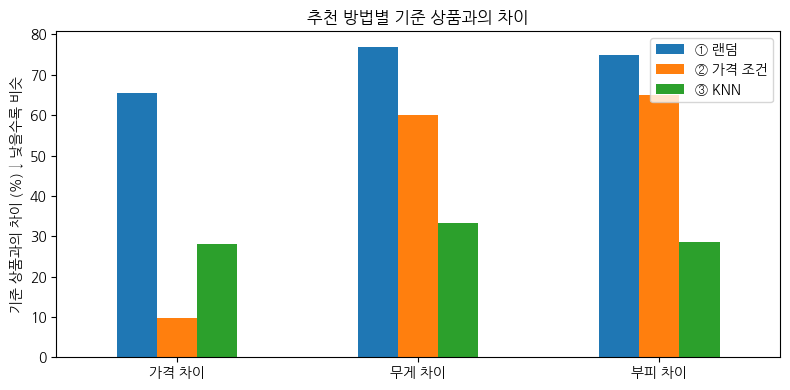

In [14]:
# 셀 14. 비교 그래프

ax = (compare[["가격 차이", "무게 차이", "부피 차이"]] * 100).T.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("기준 상품과의 차이 (%) ↓ 낮을수록 비슷")
ax.set_title("추천 방법별 기준 상품과의 차이")
ax.legend(title="")
plt.tight_layout()
plt.show()

**결과 해석**
- **① 랜덤**: 가격·무게·부피 모두 차이가 큽니다. 같은 카테고리라는 것만으로는 비슷한 상품이 나오지 않습니다.
- **② 가격 조건**: 가격 차이는 가장 작지만, 무게·부피 차이는 랜덤보다 조금 줄어들 뿐 여전히 큽니다. 그리고 조건을 붙이자마자 **후보 5개를 채우지 못하는 상품**이 생깁니다.
- **③ KNN**: 가격은 ②보다 조금 덜 맞지만, 무게·부피까지 **모든 특징을 고르게** 맞춥니다.

| 상황 | 쓸 방법 |
|---|---|
| 가격만 중요할 때 (예: "비슷한 가격대 상품 보기") | 규칙(가격 조건)으로 충분 |
| 여러 특징이 함께 비슷해야 할 때 (예: "이 상품과 비슷한 상품") | KNN |

> 💡 **복잡한 방법이 항상 필요한 것은 아닙니다.** 무엇을 기준으로 '비슷하다'고 할지 먼저 정하고, 단순한 방법과 비교해서 나아질 때 씁니다.

> ⚠️ **이 평가의 한계**: 여기서 잰 것은 "특징이 비슷한가"입니다. 고객이 실제로 추천을 클릭하거나 구매했는지는 데이터가 없어 알 수 없습니다. 실제 서비스에서는 A/B 테스트로 클릭률·구매 전환율을 확인합니다.

---
## 💾 배포용 저장

새 요청이 들어오면 **상품 ID → 같은 카테고리의 KNN → 가까운 상품 5개** 순서로 추천합니다.
그래서 스케일러, 카테고리별 KNN, 상품 목록을 **한 파일에 함께** 저장합니다.

| 저장 항목 | 역할 |
|---|---|
| `scaler` | 학습 때와 똑같은 기준으로 특징을 변환 |
| `knn_by_category` | 카테고리별로 가까운 상품을 찾는 모델 |
| `products` | 상품 ID·카테고리·특징 (추천 결과를 보여줄 때 사용) |
| `features` | 어떤 특징을 어떤 순서로 썼는지 |

In [15]:
# 셀 15. 배포용 저장 (compress=3 : 압축해서 크기 줄이기)

artifact = {
    "scaler": scaler,
    "knn_by_category": knn_by_category,
    "products": data[["product_id", "category", "category_kr"] + features].reset_index(drop=True),
    "features": features,
    "k": K,
}
save_file = f"{model_path}/part6_recommend.pkl"
joblib.dump(artifact, save_file, compress=3)
print("저장 완료 :", save_file)
print(f"파일 크기 : {os.path.getsize(save_file) / 1024:.0f} KB")

저장 완료 : /content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/model/part6_recommend.pkl
파일 크기 : 159 KB


In [16]:
# 셀 16. 저장한 파일만으로 추천해 보기 (STEP2 서빙에서 이렇게 사용합니다)

art = joblib.load(save_file)

def recommend(product_id, art=art):
    """상품 ID를 넣으면 비슷한 상품 ID 목록을 돌려줍니다."""
    prods = art["products"]
    hit = prods.index[prods["product_id"] == product_id]       # 상품 목록에서 찾기
    if len(hit) == 0:
        return []                                   # 목록에 없는 상품 (콜드 스타트)
    i = hit[0]
    x = art["scaler"].transform(np.log1p(prods.loc[[i], art["features"]]))   # 학습 때와 똑같이 로그 + 스케일링
    nn, cat_idx = art["knn_by_category"][prods.at[i, "category"]]            # 같은 카테고리 KNN
    _, pos = nn.kneighbors(x, n_neighbors=art["k"] + 1)                      # 가까운 상품 찾기
    rec = cat_idx[pos[0]]
    return prods.loc[rec[rec != i][:art["k"]], "product_id"].tolist()        # 자기 자신 빼고 k개

pid = data.at[example, "product_id"]
print("기준 상품 :", pid)
print("추천 상품 :", recommend(pid))
print("없는 상품 :", recommend("new_product_0000"))

기준 상품 : e4c7ed7a832858c17d60ad5e38b00aba
추천 상품 : ['9a469eaf45dfbc43d39ba1977a3c07af', '9fc98e39f04be8e382d8aa5e259f5489', 'f89caa3ea4fb5f7b6e7fb2bb4ba61881', '4d0ec1e9b95fb62f9a1fbe21808bf3b1', 'd3ab527ab0d134eb8a034cab8e52a589']
없는 상품 : []


---
## 마무리 정리

| 확인할 내용 | 설명 |
|---|---|
| 이 파트의 핵심 | 같은 카테고리라도 상품의 '급'은 제각각입니다. 카테고리로 종류를 맞추고, KNN으로 급을 맞춥니다. |
| 데이터 | 원본에서 거래 3건 이상 · 상위 15개 카테고리 · 약 2,500개 상품을 골랐습니다. |
| 전처리 | 치우친 값은 로그 변환, 단위가 다른 값은 스케일링 |
| 비교 | 평가 기준을 여러 개로 잡아야 공정합니다. 가격만 보면 가격 조건이 1등입니다. |
| 한계 | 특징이 비슷한지만 쟀을 뿐, 고객 반응은 모릅니다. 목록에 없는 새 상품은 추천할 수 없습니다(콜드 스타트). |
| 모델 저장 | 스케일러 + 카테고리별 KNN + 상품 목록을 한 파일로 압축 저장 |
| 다음 단계 | PART 7-1에서 리뷰 텍스트로 고객의 긍정/부정을 분류합니다. |